# E7 e E8: o agente de LLM no teste (Telecom e Bank)

Este notebook apresenta a avaliação (E8, ADR 0022) das execuções de teste da E7 (ADR 0017). As execuções foram feitas em 2026-11-19, com os pacotes de evidência do ADR 0021 (a previsora LSTM escolhe a janela).

**Configuração:**
- Claude Opus 5.5, esforço `medium`, 1 repetição por consulta;
- 45 consultas no Telecom e 120 no Bank (todas as testadas);
- teto de US$ 50 por execução.

**Variantes (mesmo modelo, mesmo prompt-base, até 20 chamadas de ferramenta):**

| Variante | O agente recebe |
|---|---|
| A0 | nada: resposta constante (E4) |
| A1 | ferramentas de telemetria, incluindo a varredura heurística `find_anomalous_kpis` |
| A2 | A1 + `get_evidence`: pontuação, limiar e alarme da previsora LSTM e ranqueamento nativo (`N#`) |
| A3 | A2 + atribuições SHAP e LIME da previsora (`C#`, `K#`) |

Também entra a **cadeia do pacote sem LLM** (ADR 0020/0021): pico do K1, componente C1 e motivo pela categoria sugerida. Ela mede o que a evidência entrega sozinha.

**De onde vêm os números:** o notebook só lê `reports/tables/agent_eval_<sistema>.json`, gerado por

```bash
uv run tcc-rca evaluate-agent --config configs/base.yaml [configs/system/bank.yaml] configs/experiment/agent_eval.yaml
```

- Toda nota vem do **script oficial do OpenRCA**. A nota parcial é a média da nota por consulta; o acerto estrito é a fração de consultas com nota 1.
- Os ICs de 95% vêm de bootstrap sobre consultas (10 000 reamostragens).
- "Superior", "inferior" e "empate" vêm da diferença **pareada**, na mesma consulta. No acerto estrito, as variantes são comparadas também pelo McNemar exato, com Holm entre as três comparações de variantes.
- A comparação principal, fixada no plano, é **A3 × A1** (RQ3). As outras são secundárias.

**Seções:**
1. nota oficial;
2. comparações pareadas;
3. tipo de tarefa;
4. acerto por campo;
5. localização (RQ2);
6. fidelidade automática (RQ4);
7. custo e uso da evidência (RQ4);
8. análise de erros;
9. reprodução e auditoria;
10. leitura.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(260)

TABLES = Path("reports/tables")
SYSTEMS = ["Telecom", "Bank"]
VARIANTS = ["A1", "A2", "A3"]
CHAINS = ["A0", "pacote", *VARIANTS]
FIELDS = ["instante", "componente", "motivo"]
E = {s: json.loads((TABLES / f"agent_eval_{s}.json").read_text(encoding="utf-8")) for s in SYSTEMS}
pl.DataFrame(
    [
        {
            "sistema": s,
            "consultas": E[s]["queries"],
            "execução E8": E[s]["run_dir"],
            **{f"E7 {v}": E[s]["runs"][v] for v in VARIANTS},
            "A0 e pacote": E[s]["evidence_select_run"],
        }
        for s in SYSTEMS
    ]
)

sistema,consultas,execução E8,E7 A1,E7 A2,E7 A3,A0 e pacote
str,i64,str,str,str,str,str
"""Telecom""",45,"""20261120T071423-agent_eval""","""20261119T194655-agent_a1""","""20261119T201255-agent_a2""","""20261119T203507-agent_a3""","""20261119T170412-evidence_select"""
"""Bank""",120,"""20261120T071429-agent_eval""","""20261119T205647-agent_a1""","""20261119T221049-agent_a2""","""20261119T232308-agent_a3""","""20261119T170508-evidence_select"""


In [2]:
LABEL = {
    "A0": "A0 constante",
    "pacote": "pacote sem LLM",
    "A1": "A1 telemetria",
    "A2": "A2 + LSTM",
    "A3": "A3 + SHAP/LIME",
}
MUTED, INK, INK2, GRID, AXIS, SURFACE = (
    "#898781",
    "#0b0b0b",
    "#52514e",
    "#e1e0d9",
    "#c3c2b7",
    "#fcfcfb",
)
COLOR = {"A0": MUTED, "pacote": INK2, "A1": "#2a78d6", "A2": "#eb6834", "A3": "#1baf7a"}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "figure.dpi": 110,
    }
)


def fmt(d, digits=2):
    return f"{d['value']:.{digits}f} [{d['ci_low']:.{digits}f}; {d['ci_high']:.{digits}f}]"


def pfmt(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def dot_ci(ax, x, y, color):
    ax.errorbar(
        x["value"],
        y,
        xerr=[[x["value"] - x["ci_low"]], [x["ci_high"] - x["value"]]],
        fmt="o",
        color=color,
        ms=8,
        elinewidth=2,
        capsize=0,
    )

### Estilo dos gráficos

Cada cadeia tem uma cor fixa em todos os gráficos:
- **cinza claro:** A0;
- **cinza escuro:** pacote sem LLM;
- **azul:** A1;
- **laranja:** A2;
- **verde-água:** A3.

A paleta é a validada para daltonismo do notebook dos modelos alternativos. O verde-água tem menos de 3:1 de contraste com o fundo, por isso todo gráfico traz o valor escrito ao lado do marcador e uma tabela.

## 1. Nota oficial por cadeia (RQ3)

sistema,cadeia,nota parcial [IC 95%],acerto estrito [IC 95%]
str,str,str,str
"""Telecom""","""A0 constante""","""0.18 [0.10; 0.29]""","""0.11 [0.02; 0.22]"""
"""Telecom""","""pacote sem LLM""","""0.41 [0.29; 0.54]""","""0.29 [0.16; 0.42]"""
"""Telecom""","""A1 telemetria""","""0.60 [0.46; 0.72]""","""0.51 [0.36; 0.67]"""
"""Telecom""","""A2 + LSTM""","""0.60 [0.48; 0.73]""","""0.49 [0.36; 0.64]"""
"""Telecom""","""A3 + SHAP/LIME""","""0.58 [0.44; 0.71]""","""0.49 [0.33; 0.64]"""
"""Bank""","""A0 constante""","""0.14 [0.09; 0.19]""","""0.08 [0.04; 0.13]"""
"""Bank""","""pacote sem LLM""","""0.35 [0.28; 0.43]""","""0.23 [0.16; 0.31]"""
"""Bank""","""A1 telemetria""","""0.43 [0.35; 0.51]""","""0.36 [0.28; 0.45]"""
"""Bank""","""A2 + LSTM""","""0.40 [0.33; 0.49]""","""0.31 [0.23; 0.39]"""


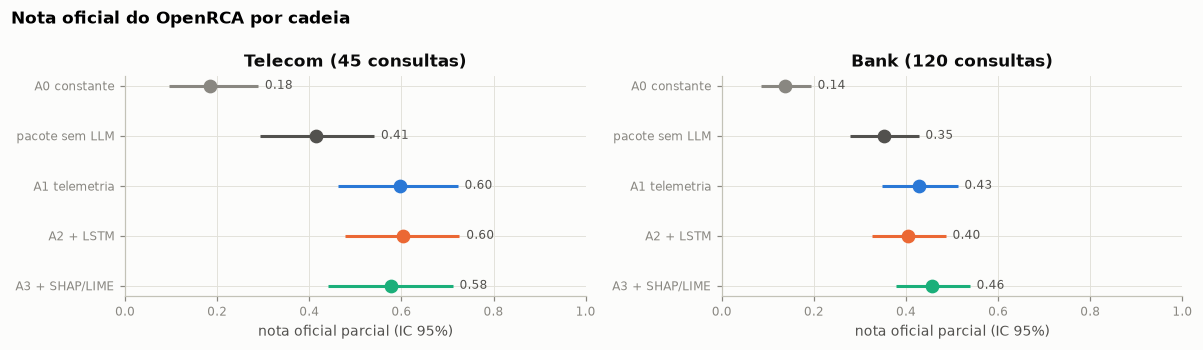

In [3]:
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "cadeia": LABEL[c],
                "nota parcial [IC 95%]": fmt(E[s]["summary"][c]["partial_score"]),
                "acerto estrito [IC 95%]": fmt(E[s]["summary"][c]["strict_accuracy"]),
            }
            for s in SYSTEMS
            for c in CHAINS
        ]
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    for i, c in enumerate(CHAINS):
        e = E[s]["summary"][c]["partial_score"]
        dot_ci(ax, e, i, COLOR[c])
        ax.text(e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(CHAINS)), [LABEL[c] for c in CHAINS])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(f"{s} ({E[s]['queries']} consultas)")
    ax.set_xlabel("nota oficial parcial (IC 95%)")
fig.suptitle(
    "Nota oficial do OpenRCA por cadeia", fontsize=11, fontweight="bold", x=0.01, ha="left"
)
fig.tight_layout()
plt.show()

## 2. Comparações pareadas

- **Diferença de nota parcial:** média da diferença na mesma consulta, com IC por bootstrap. "Superior" ou "inferior" quando o IC não contém 0.
- **McNemar exato:** no acerto estrito, *b* = consultas em que só a primeira cadeia acerta; *c* = só a segunda. O p-valor é o do teste binomial bilateral de *b* em *b + c* com p = 0,5.
- **Holm:** corrige o p das três comparações entre variantes de cada sistema. As comparações com o A0 e com o pacote são referências, sem correção.

sistema,comparação,papel,diferença parcial [IC 95%],veredito,consultas melhores / piores,McNemar b / c,p,p (Holm)
str,str,str,str,str,str,str,str,str
"""Telecom""","""A3 - A1""","""principal""","""-0.018 [-0.129; 0.093]""","""empate""","""6 / 8""","""4 / 5""","""1.000""","""1.000"""
"""Telecom""","""A2 - A1""","""secundária""","""0.008 [-0.129; 0.148]""","""empate""","""8 / 10""","""6 / 7""","""1.000""","""1.000"""
"""Telecom""","""A3 - A2""","""secundária""","""-0.026 [-0.141; 0.085]""","""empate""","""5 / 5""","""4 / 4""","""1.000""","""1.000"""
"""Telecom""","""A1 - A0""","""referência""","""0.411 [0.241; 0.567]""","""superior""","""27 / 3""","""21 / 3""","""< 0.001""","""—"""
"""Telecom""","""A1 - pacote""","""referência""","""0.182 [0.018; 0.341]""","""superior""","""20 / 9""","""14 / 4""","""0.031""","""—"""
"""Telecom""","""A2 - A0""","""referência""","""0.419 [0.256; 0.575]""","""superior""","""24 / 3""","""19 / 2""","""< 0.001""","""—"""
"""Telecom""","""A2 - pacote""","""referência""","""0.189 [0.044; 0.340]""","""superior""","""17 / 7""","""11 / 2""","""0.022""","""—"""
"""Telecom""","""A3 - A0""","""referência""","""0.393 [0.219; 0.557]""","""superior""","""26 / 4""","""20 / 3""","""< 0.001""","""—"""
"""Telecom""","""A3 - pacote""","""referência""","""0.163 [0.022; 0.304]""","""superior""","""15 / 5""","""11 / 2""","""0.022""","""—"""


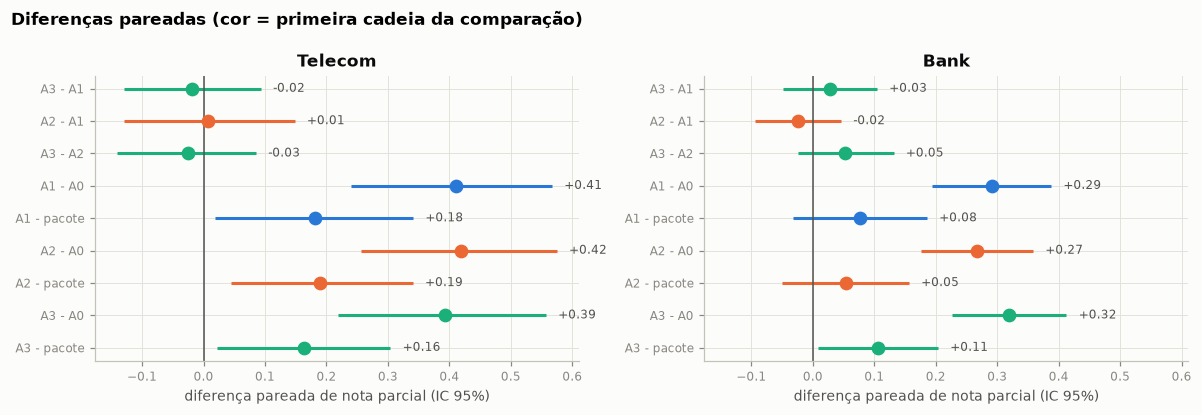

In [4]:
rows = []
for s in SYSTEMS:
    for r in [*E[s]["comparisons"], *E[s]["references"]]:
        rows.append(
            {
                "sistema": s,
                "comparação": r["comparison"],
                "papel": {"primary": "principal", "secondary": "secundária"}.get(
                    r["role"], "referência"
                ),
                "diferença parcial [IC 95%]": fmt(r["partial_difference"], 3),
                "veredito": r["verdict"],
                "consultas melhores / piores": f"{r['queries_better']} / {r['queries_worse']}",
                "McNemar b / c": f"{r['mcnemar_only_first']} / {r['mcnemar_only_second']}",
                "p": pfmt(r["mcnemar_p"]),
                "p (Holm)": pfmt(r["mcnemar_p_holm"]) if "mcnemar_p_holm" in r else "—",
            }
        )
display(pl.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    block = [*E[s]["comparisons"], *E[s]["references"]]
    for i, r in enumerate(block):
        e = r["partial_difference"]
        dot_ci(ax, e, i, COLOR[r["comparison"].split(" - ")[0]])
        ax.text(e["ci_high"] + 0.02, i, f"{e['value']:+.2f}", va="center", fontsize=8, color=INK2)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(len(block)), [r["comparison"] for r in block])
    ax.invert_yaxis()
    ax.set_title(s)
    ax.set_xlabel("diferença pareada de nota parcial (IC 95%)")
fig.suptitle(
    "Diferenças pareadas (cor = primeira cadeia da comparação)",
    fontsize=11,
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

## 3. Nota por tipo de tarefa

Os tipos do OpenRCA pedem subconjuntos diferentes de {instante, componente, motivo}:
- task_1: instante;
- task_2: motivo;
- task_3: componente;
- task_4: instante e motivo;
- task_5: instante e componente;
- task_6: componente e motivo;
- task_7: os três.

Com poucas consultas por tipo, a tabela é descritiva, sem IC.

In [5]:
FIELDS_OF = {
    "task_1": "instante",
    "task_2": "motivo",
    "task_3": "componente",
    "task_4": "instante + motivo",
    "task_5": "instante + componente",
    "task_6": "componente + motivo",
    "task_7": "os três",
}
for s in SYSTEMS:
    print(s)
    display(
        pl.DataFrame(
            [
                {"tarefa": t, "campos": FIELDS_OF[t], "n": d["n"]}
                | {LABEL[c]: round(d[c], 2) for c in CHAINS}
                for t, d in E[s]["by_task"].items()
            ]
        )
    )

Telecom


tarefa,campos,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,str,i64,f64,f64,f64,f64,f64
"""task_1""","""instante""",9,0.0,0.33,0.89,0.78,0.78
"""task_2""","""motivo""",7,0.57,0.43,0.29,0.57,0.29
"""task_3""","""componente""",4,0.25,0.75,0.25,0.5,0.5
"""task_4""","""instante + motivo""",7,0.07,0.36,0.64,0.57,0.5
"""task_5""","""instante + componente""",4,0.0,0.62,0.62,0.62,0.62
"""task_6""","""componente + motivo""",6,0.25,0.17,0.58,0.5,0.5
"""task_7""","""os três""",8,0.17,0.46,0.67,0.58,0.75


Bank


tarefa,campos,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,str,i64,f64,f64,f64,f64,f64
"""task_1""","""instante""",20,0.05,0.42,0.3,0.25,0.4
"""task_2""","""motivo""",17,0.29,0.47,0.35,0.41,0.29
"""task_3""","""componente""",14,0.21,0.29,0.36,0.14,0.43
"""task_4""","""instante + motivo""",17,0.12,0.43,0.41,0.51,0.62
"""task_5""","""instante + componente""",16,0.09,0.33,0.45,0.44,0.41
"""task_6""","""componente + motivo""",19,0.16,0.18,0.68,0.61,0.55
"""task_7""","""os três""",17,0.06,0.33,0.42,0.43,0.49


## 4. Acerto por campo (aproximado)

Cada critério do gabarito oficial (uma linha por campo e por falha) conta como acerto se o valor esperado está entre os acertos do relatório oficial. É uma leitura **aproximada**: em consultas com duas falhas, o script oficial escolhe a melhor associação entre causas, e aqui cada critério é contado separadamente. Os ICs vêm de bootstrap sobre consultas.

sistema,cadeia,instante,componente,motivo,critérios (instante/componente/motivo)
str,str,str,str,str,str
"""Telecom""","""A0 constante""","""0.00 [0.00; 0.00]""","""0.18 [0.05; 0.36]""","""0.32 [0.14; 0.50]""","""28 / 22 / 28"""
"""Telecom""","""pacote sem LLM""","""0.50 [0.32; 0.68]""","""0.41 [0.23; 0.64]""","""0.32 [0.14; 0.50]""","""28 / 22 / 28"""
"""Telecom""","""A1 telemetria""","""0.71 [0.54; 0.86]""","""0.68 [0.50; 0.86]""","""0.46 [0.29; 0.64]""","""28 / 22 / 28"""
"""Telecom""","""A2 + LSTM""","""0.64 [0.46; 0.82]""","""0.73 [0.55; 0.91]""","""0.43 [0.25; 0.61]""","""28 / 22 / 28"""
"""Telecom""","""A3 + SHAP/LIME""","""0.68 [0.50; 0.86]""","""0.73 [0.55; 0.91]""","""0.43 [0.25; 0.61]""","""28 / 22 / 28"""
"""Bank""","""A0 constante""","""0.04 [0.00; 0.08]""","""0.13 [0.06; 0.21]""","""0.16 [0.08; 0.24]""","""82 / 76 / 77"""
"""Bank""","""pacote sem LLM""","""0.41 [0.32; 0.51]""","""0.26 [0.17; 0.36]""","""0.34 [0.23; 0.45]""","""82 / 76 / 77"""
"""Bank""","""A1 telemetria""","""0.37 [0.26; 0.47]""","""0.54 [0.42; 0.65]""","""0.44 [0.33; 0.55]""","""82 / 76 / 77"""
"""Bank""","""A2 + LSTM""","""0.43 [0.32; 0.53]""","""0.50 [0.38; 0.62]""","""0.45 [0.34; 0.57]""","""82 / 76 / 77"""


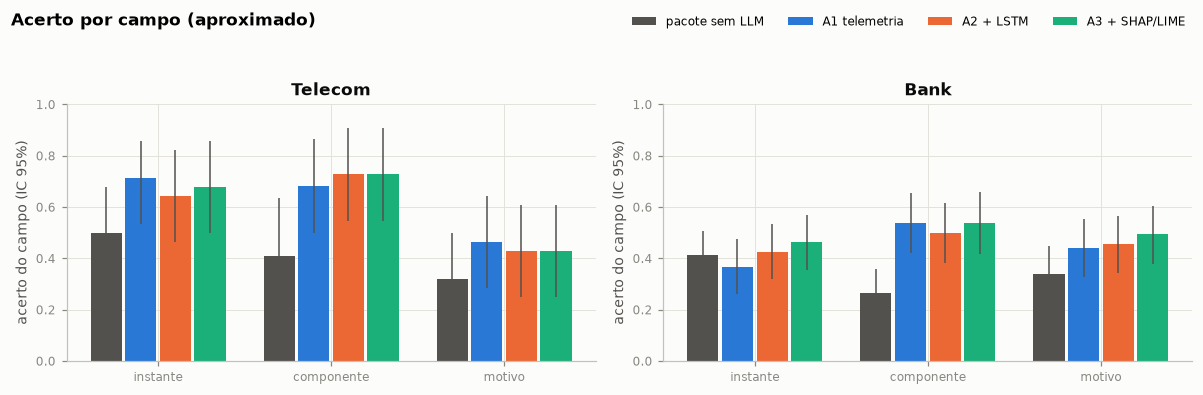

In [6]:
rows = []
for s in SYSTEMS:
    for c in CHAINS:
        f = E[s]["summary"][c]["fields"]
        counts = " / ".join(str(f[k]["criteria"]) for k in FIELDS)
        rows.append(
            {"sistema": s, "cadeia": LABEL[c]}
            | {k: fmt(f[k]) for k in FIELDS}
            | {"critérios (instante/componente/motivo)": counts}
        )
display(pl.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
width = 0.2
for ax, s in zip(axes, SYSTEMS, strict=True):
    for j, c in enumerate(CHAINS[1:]):
        for k, f in enumerate(FIELDS):
            e = E[s]["summary"][c]["fields"][f]
            x = k + (j - 1.5) * width
            ax.bar(
                x, e["value"], width=width * 0.9, color=COLOR[c], label=LABEL[c] if k == 0 else None
            )
            ax.vlines(x, e["ci_low"], e["ci_high"], color=INK2, lw=1)
    ax.set_xticks(range(len(FIELDS)), FIELDS)
    ax.set_ylim(0, 1)
    ax.set_title(s)
    ax.set_ylabel("acerto do campo (IC 95%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=4, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Acerto por campo (aproximado)", fontsize=11, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 5. Localização do componente (RQ2)

Esta seção usa só as consultas com uma falha que pedem o componente: 22 no Telecom e 56 no Bank. Ela compara o componente respondido pelo agente com o C1 do pacote (o componente mais atribuído pelo SHAP da previsora) nas mesmas consultas.
- No McNemar, *b* = só o agente acerta e *c* = só o C1 acerta.
- O HR@1 da E6 (0,42 no Telecom e 0,48 no Bank) foi medido nas **janelas-oráculo**, com o início rotulado. Aqui a janela é a que o detector escolhe dentro da consulta, por isso os números não são diretamente comparáveis.

In [7]:
rows = []
for s in SYSTEMS:
    loc = E[s]["localization"]
    rows.append(
        {
            "sistema": s,
            "consultas": loc["queries"],
            "cadeia": "pacote (C1)",
            "HR@1 [IC 95%]": fmt(loc["pacote"]),
            "menos o C1": "—",
            "veredito": "—",
            "McNemar b / c / p": "—",
        }
    )
    for v in VARIANTS:
        x = loc[v]
        b, c, p = x["mcnemar"]
        rows.append(
            {
                "sistema": s,
                "consultas": loc["queries"],
                "cadeia": LABEL[v],
                "HR@1 [IC 95%]": fmt(x),
                "menos o C1": fmt(x["minus_pacote"]),
                "veredito": x["verdict"],
                "McNemar b / c / p": f"{b} / {c} / {pfmt(p)}",
            }
        )
display(pl.DataFrame(rows))

sistema,consultas,cadeia,HR@1 [IC 95%],menos o C1,veredito,McNemar b / c / p
str,i64,str,str,str,str,str
"""Telecom""",22,"""pacote (C1)""","""0.41 [0.23; 0.64]""","""—""","""—""","""—"""
"""Telecom""",22,"""A1 telemetria""","""0.68 [0.50; 0.86]""","""0.27 [-0.05; 0.59]""","""empate""","""10 / 4 / 0.180"""
"""Telecom""",22,"""A2 + LSTM""","""0.73 [0.55; 0.91]""","""0.32 [0.09; 0.55]""","""superior""","""8 / 1 / 0.039"""
"""Telecom""",22,"""A3 + SHAP/LIME""","""0.73 [0.55; 0.91]""","""0.32 [0.09; 0.55]""","""superior""","""8 / 1 / 0.039"""
"""Bank""",56,"""pacote (C1)""","""0.25 [0.14; 0.38]""","""—""","""—""","""—"""
"""Bank""",56,"""A1 telemetria""","""0.55 [0.43; 0.68]""","""0.30 [0.16; 0.45]""","""superior""","""20 / 3 / < 0.001"""
"""Bank""",56,"""A2 + LSTM""","""0.45 [0.32; 0.57]""","""0.20 [0.05; 0.34]""","""superior""","""14 / 3 / 0.013"""
"""Bank""",56,"""A3 + SHAP/LIME""","""0.50 [0.38; 0.62]""","""0.25 [0.12; 0.39]""","""superior""","""16 / 2 / 0.001"""


## 6. Fidelidade automática das explicações (RQ4)

Cada explicação é conferida com as saídas das ferramentas da **própria** transcrição, sem gabarito:
- **IDs:** `T#`, `C#`, `K#` e `N#` escritos no texto que nenhuma ferramenta emitiu;
- **componentes:** nomes com o formato de componente do sistema (mesmo prefixo de tipo) que não existem no sistema nem nas saídas;
- **identificadores:** nomes de KPI (com `_`) que não aparecem em nenhum KPI do catálogo, mesmo abreviados, nem nas saídas, nem entre as ferramentas;
- **números:** valores declarados sem correspondência numérica nas saídas.
  - A tolerância é de uma unidade da última casa escrita, o que cobre arredondamento e truncamento. Só valores marcados como aproximados ("cerca de", "~") aceitam 5%.
  - Ficam de fora horários, datas, IDs e inteiros menores que 100 (contagens, minutos, porcentagens).
  - Números derivados (diferenças, razões) também contam como sem lastro. A taxa é, portanto, um teto para valores inventados.

**Controle de acaso:** os mesmos números multiplicados por 1,37 encontram correspondência em cerca de 1 em cada 4 casos. Essa é a taxa que a regra teria por coincidência; a dos números reais fica perto de 99%.

In [8]:
rows = []
for s in SYSTEMS:
    for v in VARIANTS:
        f = E[s]["fidelity"][v]
        row = {"sistema": s, "variante": v, "explicações": f["explanations"]}
        for k, name in (
            ("ids", "IDs não emitidos"),
            ("components", "componentes desconhecidos"),
            ("identifiers", "identificadores desconhecidos"),
            ("numbers", "números sem lastro"),
        ):
            row[name] = f"{f[k]['flagged']} / {f[k]['checked']}"
        row["números: explicações com algum"] = f["numbers"]["explanations_flagged"]
        row["números: taxa [IC 95%]"] = fmt(f["numbers"]["flagged_rate"], 3)
        row["controle (x1,37) com lastro"] = f"{f['numbers']['control_grounded_rate']:.2f}"
        rows.append(row)
display(pl.DataFrame(rows))

sistema,variante,explicações,IDs não emitidos,componentes desconhecidos,identificadores desconhecidos,números sem lastro,números: explicações com algum,números: taxa [IC 95%],"controle (x1,37) com lastro"
str,str,i64,str,str,str,str,i64,str,str
"""Telecom""","""A1""",45,"""0 / 519""","""0 / 347""","""0 / 210""","""5 / 361""",4,"""0.014 [0.003; 0.029]""","""0.27"""
"""Telecom""","""A2""",45,"""0 / 531""","""0 / 344""","""0 / 223""","""1 / 419""",1,"""0.002 [0.000; 0.008]""","""0.21"""
"""Telecom""","""A3""",45,"""0 / 774""","""0 / 332""","""0 / 198""","""5 / 483""",4,"""0.010 [0.002; 0.022]""","""0.22"""
"""Bank""","""A1""",120,"""0 / 1221""","""0 / 920""","""0 / 115""","""11 / 1203""",11,"""0.009 [0.004; 0.015]""","""0.27"""
"""Bank""","""A2""",120,"""0 / 1519""","""0 / 901""","""0 / 90""","""13 / 1449""",8,"""0.009 [0.003; 0.016]""","""0.25"""
"""Bank""","""A3""",120,"""0 / 2018""","""0 / 830""","""0 / 100""","""9 / 1522""",6,"""0.006 [0.001; 0.011]""","""0.22"""


## 7. Custo e uso da evidência (RQ4)

Por consulta: custo em US$ (preços de 2026-11-03), latência somada das chamadas, chamadas de ferramenta. Média ± desvio-padrão entre consultas. Nenhuma chamada da E7 veio do cache. No gráfico, o A0 e o pacote aparecem com custo zero, porque não chamam o LLM.

sistema,variante,US$ total,US$/consulta,latência/consulta (s),ferramentas/consulta,respostas válidas,válidas após nova tentativa,usa get_evidence,usa find_anomalous_kpis,cita N# / C# / K#
str,str,f64,str,str,str,f64,i64,i64,i64,str
"""Telecom""","""A1""",8.69,"""0.193 ± 0.061""","""34.0 ± 9.6""","""13.2 ± 4.5""",1.0,5,0,45,"""0 / 0 / 0"""
"""Telecom""","""A2""",7.55,"""0.168 ± 0.079""","""29.0 ± 11.5""","""10.8 ± 5.8""",1.0,6,45,45,"""45 / 0 / 0"""
"""Telecom""","""A3""",7.3,"""0.162 ± 0.071""","""28.3 ± 10.7""","""9.8 ± 5.3""",1.0,1,45,45,"""45 / 44 / 45"""
"""Bank""","""A1""",27.83,"""0.232 ± 0.114""","""36.4 ± 14.0""","""12.4 ± 6.6""",1.0,15,0,120,"""0 / 0 / 0"""
"""Bank""","""A2""",26.02,"""0.217 ± 0.111""","""35.5 ± 14.4""","""12.1 ± 6.4""",1.0,11,120,120,"""118 / 0 / 0"""
"""Bank""","""A3""",26.49,"""0.221 ± 0.107""","""36.2 ± 14.9""","""12.0 ± 6.4""",1.0,10,120,120,"""119 / 119 / 119"""


custo total da E7 (6 execuções): US$ 103.88


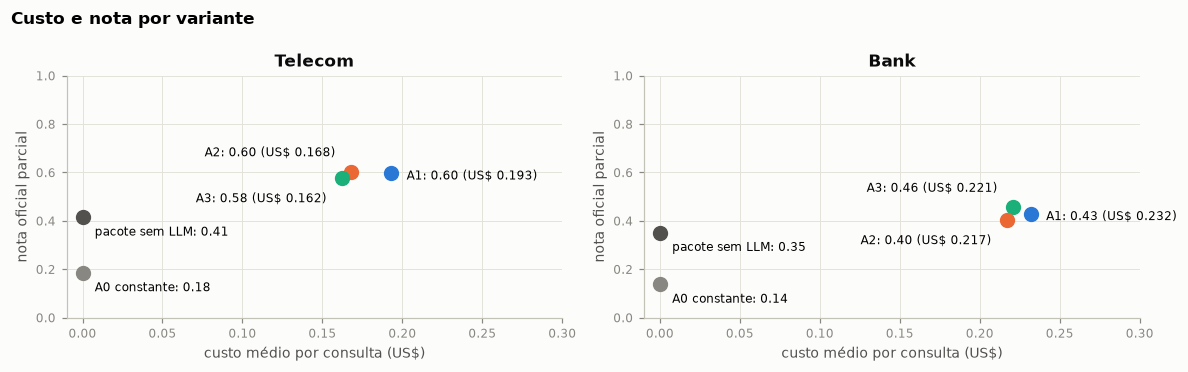

In [9]:
rows, points = [], []
for s in SYSTEMS:
    for v in VARIANTS:
        x = E[s]["cost"][v]
        rows.append(
            {
                "sistema": s,
                "variante": v,
                "US$ total": round(x["cost_usd"], 2),
                "US$/consulta": f"{x['cost_usd_mean']:.3f} ± {x['cost_usd_sd']:.3f}",
                "latência/consulta (s)": f"{x['latency_s_mean']:.1f} ± {x['latency_s_sd']:.1f}",
                "ferramentas/consulta": f"{x['tool_calls_mean']:.1f} ± {x['tool_calls_sd']:.1f}",
                "respostas válidas": x["valid_rate"],
                "válidas após nova tentativa": x["valid_after_retry"],
                "usa get_evidence": x["evidence_tool_use"],
                "usa find_anomalous_kpis": x["scan_tool_use"],
                "cita N# / C# / K#": f"{x['cites']['N']} / {x['cites']['C']} / {x['cites']['K']}",
            }
        )
        points.append((s, v, x["cost_usd_mean"], E[s]["summary"][v]["partial_score"]["value"]))
display(pl.DataFrame(rows))
total = sum(E[s]["cost"][v]["cost_usd"] for s in SYSTEMS for v in VARIANTS)
print(f"custo total da E7 (6 execuções): US$ {total:.2f}")

# label placement by score rank inside each panel: top above, middle right, bottom below
OFFSET = [(-10, 10, "right"), (10, -4, "left"), (-10, -16, "right")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, s in zip(axes, SYSTEMS, strict=True):
    mine = sorted((p for p in points if p[0] == s), key=lambda p: -p[3])
    for rank, (_, v, cost, score) in enumerate(mine):
        ax.plot(cost, score, "o", color=COLOR[v], ms=9)
        dx, dy, ha = OFFSET[rank]
        ax.annotate(
            f"{v}: {score:.2f} (US$ {cost:.3f})",
            (cost, score),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=8,
            ha=ha,
        )
    for ref in ("A0", "pacote"):
        y = E[s]["summary"][ref]["partial_score"]["value"]
        ax.plot(0, y, "o", color=COLOR[ref], ms=9)
        ax.annotate(
            f"{LABEL[ref]}: {y:.2f}",
            (0, y),
            xytext=(8, -12),
            textcoords="offset points",
            fontsize=8,
        )
    ax.set_xlim(-0.01, 0.3)
    ax.set_ylim(0, 1)
    ax.set_title(s)
    ax.set_xlabel("custo médio por consulta (US$)")
    ax.set_ylabel("nota oficial parcial")
fig.suptitle("Custo e nota por variante", fontsize=11, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 8. Análise de erros

Acerto por **motivo esperado** (critérios de motivo) e por **tipo do componente esperado** (critérios de componente). Os grupos são pequenos, e a leitura é descritiva.

In [10]:
for s in SYSTEMS:
    for key, title in (
        ("by_reason", "motivo esperado"),
        ("by_component_type", "tipo de componente"),
    ):
        print(f"{s}: {title}")
        display(
            pl.DataFrame(
                [
                    {title: g, "n": d["n"]} | {LABEL[c]: round(d[c], 2) for c in CHAINS}
                    for g, d in E[s]["errors"][key].items()
                ]
            )
        )

Telecom: motivo esperado


motivo esperado,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,i64,f64,f64,f64,f64,f64
"""CPU fault""",9,1.0,0.44,0.56,0.44,0.56
"""db close""",4,0.0,0.5,1.0,1.0,1.0
"""db connection limit""",4,0.0,0.25,0.25,0.0,0.25
"""network delay""",6,0.0,0.17,0.33,0.67,0.33
"""network loss""",5,0.0,0.2,0.2,0.0,0.0


Telecom: tipo de componente


tipo de componente,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,i64,f64,f64,f64,f64,f64
"""db""",7,0.57,0.29,0.57,0.71,0.71
"""docker""",5,0.0,0.0,1.0,0.8,0.8
"""os""",10,0.0,0.7,0.6,0.7,0.7


Bank: motivo esperado


motivo esperado,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,i64,f64,f64,f64,f64,f64
"""JVM Out of Memory (OOM) Heap""",1,0.0,0.0,0.0,0.0,0.0
"""high CPU usage""",19,0.32,0.37,0.89,0.89,0.95
"""high disk I/O read usage""",12,0.0,0.58,0.5,0.5,0.5
"""high disk space usage""",5,0.0,0.0,0.4,1.0,0.6
"""high memory usage""",2,1.0,0.0,1.0,1.0,1.0
"""network latency""",14,0.0,0.0,0.0,0.14,0.07
"""network packet loss""",24,0.17,0.5,0.29,0.12,0.33


Bank: tipo de componente


tipo de componente,n,A0 constante,pacote sem LLM,A1 telemetria,A2 + LSTM,A3 + SHAP/LIME
str,i64,f64,f64,f64,f64,f64
"""IG""",10,0.0,0.1,1.0,0.8,0.7
"""MG""",16,0.0,0.12,0.5,0.38,0.38
"""Mysql""",4,0.0,0.25,0.25,0.5,0.75
"""Redis""",1,0.0,0.0,0.0,0.0,0.0
"""Tomcat""",33,0.3,0.36,0.58,0.45,0.67
"""apache""",12,0.0,0.33,0.25,0.58,0.25


## 9. Reprodução a partir do cache e auditoria manual

- **Reprodução:** cada execução da E7 foi refeita a partir do cache do LLM, com teto de US$ 0 (`configs/experiment/agent_a*_replay.yaml`). O critério da E7 exige 0 chamadas pagas e previsões e `metrics.json` iguais aos originais.
- **Auditoria manual:** a planilha cega de 120 afirmações (30 explicações) está em `reports/audit/`, e a rubrica em `docs/AUDITORIA_FIDELIDADE.md`. Os números aparecem aqui depois que o autor a preencher e reexecutar o `evaluate-agent`.

In [11]:
display(
    pl.DataFrame(
        [
            {"sistema": s, "variante": v}
            | {
                k: r[k]
                for k in (
                    "replay_run",
                    "paid_calls",
                    "cache_hits",
                    "same_predictions",
                    "same_metrics",
                )
            }
            for s in SYSTEMS
            for v, r in E[s]["replay"].items()
        ]
    )
)
for s in SYSTEMS:
    a = E[s]["audit"]
    print(f"{s}: {a['system_classified']} de {a['system_claims']} afirmações auditadas")
if E["Bank"]["audit"]["classified"]:
    display(E["Bank"]["audit"]["by_variant"])

sistema,variante,replay_run,paid_calls,cache_hits,same_predictions,same_metrics
str,str,str,i64,i64,bool,bool
"""Telecom""","""A1""","""20261120T070324-agent_a1_replay""",0,368,true,true
"""Telecom""","""A2""","""20261120T070349-agent_a2_replay""",0,298,true,true
"""Telecom""","""A3""","""20261120T070410-agent_a3_replay""",0,271,true,true
"""Bank""","""A1""","""20261120T070431-agent_a1_replay""",0,931,true,true
"""Bank""","""A2""","""20261120T070533-agent_a2_replay""",0,915,true,true
"""Bank""","""A3""","""20261120T070632-agent_a3_replay""",0,889,true,true


Telecom: 0 de 60 afirmações auditadas
Bank: 0 de 60 afirmações auditadas


## 10. Leitura

- **O LLM acrescenta muito à evidência sozinha (RQ3).**
  - As três variantes são superiores ao A0 nos dois sistemas.
  - No Telecom, as três também superam a cadeia do pacote sem LLM. No Bank, só a A3 é superior a ela; a A1 e a A2 empatam.
  - O maior ganho é no componente. Nas consultas de uma falha, todas as variantes localizam melhor que o C1 do pacote, exceto a A1 no Telecom, que empata. Quando o agente e o C1 discordam, quem acerta é quase sempre o agente.
- **A evidência LSTM/XAI não teve efeito mensurável no agente (RQ3).**
  - A comparação principal, A3 × A1, dá empate nos dois sistemas, pela diferença pareada e pelo McNemar (p = 1,0).
  - As comparações secundárias (A2 × A1 e A3 × A2) também dão empate.
  - No Bank, a ordem A3 > A1 > A2 e o acerto por campo sugerem um efeito pequeno do SHAP/LIME no instante e no motivo, dentro do ruído.
- **O agente usa a evidência, mas não depende dela.** A2 e A3 chamam `get_evidence` em todas as consultas, e a A3 cita `C#`/`K#` em quase todas. Mesmo assim, todas as variantes rodam a varredura heurística `find_anomalous_kpis` em 100% das consultas.
- **Fidelidade (RQ4, parte automática):**
  - nenhuma explicação cita um ID que não recebeu, nem um componente ou KPI inexistente;
  - cerca de 1% dos números declarados não tem correspondência nas saídas das ferramentas, contra cerca de 75% sem correspondência no controle de acaso.
  - A auditoria manual vai dizer se as afirmações inteiras são sustentadas.
- **Custo:** de US$ 0,16 a 0,23 por consulta. No Telecom, a A2 e a A3 custam um pouco menos que a A1, porque fazem menos chamadas de ferramenta. No Bank, custam o mesmo.
- **Onde o agente erra:** falhas de rede. No Bank, latência de rede tem acerto de motivo de 0 a 0,14 em todas as cadeias, e perda de pacotes (0,12 a 0,33) fica abaixo do pacote (0,50). No Telecom, perda de rede fica entre 0 e 0,2. O atraso de rede varia muito entre variantes (0,33 a 0,67, com só 6 critérios).

### Ameaças a considerar

- **Contaminação (nº 15):** o OpenRCA é público, e o modelo pode conhecer o benchmark. Isso favorece todas as variantes igualmente; a comparação entre variantes controla parte do efeito.
- **Varredura heurística em todas as variantes (nº 17):** "sem LSTM" não quer dizer "sem detector".
- **Uma repetição (nº 25):** a variância entre execuções do LLM não foi medida.
- **Poder estatístico (nº 25):** com 45 consultas no Telecom, diferenças de até cerca de 0,13 na nota parcial passam por empate.
- **Auditoria por uma pessoa, cegamento parcial (nº 26).**
- **Pacotes trocados depois do teste da E5 (ADR 0021, nº 11):** a troca foi fixada antes de medir os pacotes e antes de qualquer execução do agente.